# Timestral, zero-shot

This notebook asks one question: **can a pretrained forecasting model, used as it comes, forecast the size of Bitcoin's hourly moves as well as the models trained on our data?** The model is Timestral, the family of time-series foundation models that Mistral released on 15 October 2026. *Zero-shot* means that its weights never see our data: the notebook only chooses, on the validation block, which series the model reads, how much history, which covariates and which model size.

## Main results

| Question | Timestral (chosen on validation) | Test result | Classical reference (refitted here) | Verdict |
|---|---|---|---|---|
| Size of each of the next 24 hours (\|r\|) | average of Timestral 28M (\|r\|, 180 days, clock + releases + range and volume) and Gradient Boosting refitted every month | R² **0.164** (Timestral alone 0.157) | Gradient Boosting refitted every month: R² 0.148 | **better (+0.016, reliable)**; Timestral alone +0.009, reliable |
| 80% range for each hour | Timestral's own q10–q90 (+ rolling conformal) | coverage 80.3% raw (79.9% calibrated), width 0.99%, **release hours 70%** | Gradient Boosting quantile + rolling conformal: coverage 79.9%, width 0.98%, release hours 56% | tie overall, without any calibration; **better in release hours** |
| 24 hourly returns (the median of the forecast) | Timestral, series r | MAE skill −0.0015 | zero forecast (Gradient Boosting q50: −0.0007) | nothing beats predicting 0% |

**In short:** used as it comes, with nothing fitted on our data, the smallest Timestral forecasts the size of Bitcoin's hourly moves better than every single model trained on it: R² 0.157, against 0.148 for Gradient Boosting refitted every month and 0.156 for the best network of `neural-models.ipynb`, an LSTM fine-tuned every month. Averaged with Gradient Boosting it reaches 0.164. Its 80% ranges are honest without calibration, and in release hours they are wider and cover 70% of the moves, against 56% for the classical ranges. The returns themselves stay unpredictable. The caveat below applies: the test block may be in Timestral's training data.

## Timestral

| | |
|---|---|
| **Models** | 5M, 28M, 123M and 209M parameters, one architecture; weights of 21 MB, 111 MB, 490 MB and 837 MB (fp32) |
| **Output** | 21 quantiles (1%, 5%, 10%, …, 90%, 95%, 99%) of every forecast step |
| **Inputs** | the target series (NaN = missing), past-only covariates and known-future covariates (numbers, 0/1 indicators or categories) |
| **Context** | up to 32,768 steps, read in patches of 32 steps: the 24 predicted hours are one patch |
| **Training** | mostly synthetic series, then a mix of real and synthetic series that Mistral does not list |
| **Code and weights** | `github.com/mistralai/timestral` (Apache 2.0, inference only) · Hugging Face `mistralai/Timestral-28M`, `-209M`, … (modified MIT license) |

**Setup.** `pip install -r requirements.txt` installs the `timestral` package, pinned to a commit of its GitHub repository. The weights are downloaded to the Hugging Face cache the first time a model is used: `MODEL` (28M, 111 MB) and the models of `EXTRA_MODELS` (empty by default; 209M is 837 MB). Every Timestral forecast and the monthly Gradient Boosting refit are saved in `data/timestral_cache/` (`CACHE_DIR`), so a rerun only computes what changed.

## What is chosen, and how

Nothing is trained, but there are still choices. All of them are made on the validation block (Jan 2023 → Jun 2024):

| Choice | Options | Stage |
|---|---|---|
| input series | the hourly return r, or its size \|r\| | A |
| context | the last 30, 90 or 180 days | A |
| covariates | clock (as categories or as numbers), release hours (B5), range and volume of each past hour | B: one group at a time, kept if the validation R² improves |
| model size | 28M; optionally the chosen setting with a larger model (`EXTRA_MODELS`, off by default) | C |
| rescaling | none, or \|r\| ≈ a + b × forecast, fitted on train origins (refitted on train + validation for the test) | every run |

The rescaling is the only thing fitted on our data: two numbers. The chosen setting is then run **once** on the test block. The averages of Timestral and Gradient Boosting are candidates from the start and are chosen on validation like the rest (`neural-models.ipynb`, section 8.4, explains why a choice made after looking at the test is not a result).

## Caveat: the test block may be in the training data

Timestral was released after the end of our test block (8 Oct 2026), and Mistral does not say which real series it used. If Bitcoin prices of 2023–2026 are among them, the validation and test blocks are not out-of-sample for the model, and its results here may be optimistic. This cannot be checked from outside.

## Rules

The rules of `classical-models.ipynb` and `neural-models.ipynb`: the same data (1 Jan 2020 → 8 Oct 2026), forecast origins, blocks (cut by the date of the predicted hours, with a 192-hour purge before each border) and test days, so every number here can be compared with theirs. The classical references are refitted here on the same rows, so the differences can be tested with the block bootstrap.

**Run time:** 62 minutes on an RTX 5060 Laptop GPU (8 GB), most of it the Timestral forecast of the test block (27 min) and the monthly Gradient Boosting refits (15 min, CPU). Both are cached in `data/timestral_cache/`, so a rerun takes a few minutes.

## 1. Settings, data and blocks

*Setup: to see the results, skip to section 3.*

Run the notebook from the repo root, so that `data/` and `utils/` are found. Sections 1.1–1.3 repeat sections 1.1–1.3 of `neural-models.ipynb`, so the forecast origins, the blocks and the long-format rows are identical.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # conda's MKL numpy and pip's torch each ship libiomp5md.dll (model_test.ipynb)
import hashlib
import json
import re
import sys
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from timestral import TimestralForecaster

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.config import DATA_START, TEST_START, VAL_START
from utils.features import TARGET_HOUR_FEATURES, load_releases, target_hour_features
from utils.saving import ModelSaver

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
WINDOW = pd.Timedelta(hours=192)            # purge before each border (168 input + 24 target hours, versions 2-3)
STRIDE = 6                                  # train and validation keep every 6th forecast origin
RANDOM_STATE = 42
MODEL = "mistralai/Timestral-28M"           # stages A and B (111 MB download)
EXTRA_MODELS = []                           # stage C: the chosen setting with larger models, e.g. ["mistralai/Timestral-209M"]
                                            # (837 MB; run of 25 Oct 2026: val R2 +0.005 for 7x the time, section 3.2)
REVISIONS = {}                              # {repo: Hugging Face commit hash}, to pin the weights of a rerun
CONTEXTS = (720, 2160, 4320)                # hours of history the model reads: 30, 90 and 180 days
BATCH = 256                                 # rows (origins x series and covariates) per forward pass: Timestral's
                                            # attention across rows is quadratic in this number (8 GB GPU)
RUN_GB_REFIT = True                         # Gradient Boosting refitted every month (about 15 min of CPU, then cached)
Q_STRIDE = 6                                # section 4 keeps every 6th test origin: ranges need far fewer rows than R2
CACHE_DIR = os.path.join("data", "timestral_cache")   # forecasts saved here, so a rerun loads them; None turns it off
EXPORT_DIR = "models"                       # section 3.6 saves the models in EXPORT_DIR/<name of the best model>/
SAVE_MODELS = True                          # the other trained models (section 4) go to models/timestral-zero-shot/
save = ModelSaver("timestral-zero-shot", enabled=SAVE_MODELS)   # save(name, model) -> model (utils/saving.py)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_START = time.time()
np.random.seed(RANDOM_STATE)
print(f"PyTorch {torch.__version__}, device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Colours and axes style shared by the plots (as in classical-models.ipynb)
BLUE, ORANGE, AQUA, GREY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e", "#6250d6"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def digest(a):
    # short fingerprint of an array, for the cache keys
    return hashlib.md5(np.ascontiguousarray(a).tobytes()).hexdigest()[:12]


def cached(key, fn):
    # fn() (an array), saved in CACHE_DIR under a hash of `key` (a tuple naming every input), so a rerun loads it
    if CACHE_DIR is None:
        return fn()
    path = os.path.join(CACHE_DIR, hashlib.md5(repr(key).encode()).hexdigest()[:16] + ".npy")
    if os.path.exists(path):
        return np.load(path)
    out = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    np.save(path, out)
    return out

PyTorch 2.14.1+cu130, device: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


### 1.1 Data and forecast origins

As in `neural-models.ipynb` (section 1.1): `Return` in percent, every hour with 30 days of history and 24 hours after it is a forecast origin, and `y_all[i, h]` is the return of hour *h* + 1 after origin *i*. The features are computed only to find the same first origin and for the Gradient Boosting references; Timestral reads the hourly series itself (section 2).

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True).loc[DATA_START:].copy()
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
ret, absr = hourly["Return"].values, hourly["Return"].abs().values

F_base, F_b1, F_b2 = U.base_features(hourly), U.long_lookback_features(hourly), U.range_vol_features(hourly)
FEAT = pd.concat([F_base, F_b1, F_b2], axis=1)
BASE = list(F_base.columns)

# forecast origins: every hour with all features defined (30 days of history) and 24 hours after it
ok = np.isfinite(FEAT.values).all(axis=1)
first = int(np.argmax(ok))
assert ok[first:].all(), "missing feature values inside the series"
pos_all = np.arange(first, len(hourly) - U.H_AHEAD)
origins = hourly.index[pos_all]
y_all = np.stack([ret[pos_all + k] for k in range(1, U.H_AHEAD + 1)], axis=1)     # next 24 returns, %

releases = load_releases()
B5 = list(TARGET_HOUR_FEATURES)
print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
print(f"{len(origins):,} forecast origins   {origins[0]} -> {origins[-1]}")

59,331 hours   2020-01-01 00:00:00 -> 2026-10-08 02:00:00
58,588 forecast origins   2020-01-30 23:00:00 -> 2026-10-07 02:00:00


### 1.2 The three blocks

As in `neural-models.ipynb` (section 1.2): train and validation keep every 6th origin, test keeps every origin, and `test_days` (one origin per day, at 23:00) are the independent days of the bootstrap. One more set is added:

- **`cal`**: every 5th train origin (one every 30 hours, so the hour of the origin rotates), on which the optional rescaling of Timestral's forecast is fitted. Two numbers need far fewer rows than a model, and each Timestral run forecasts these origins too.

In [3]:
start_hour = origins + pd.Timedelta(hours=1)              # first predicted hour
day_end = origins + pd.Timedelta(hours=U.H_AHEAD)         # last predicted hour
in_train = np.flatnonzero(day_end < VAL_START - WINDOW)
in_val = np.flatnonzero((start_hour >= VAL_START) & (day_end < TEST_START - WINDOW))
blk = {
    "train": in_train[::STRIDE],
    "val": in_val[::STRIDE],
    "test": np.flatnonzero(start_hour >= TEST_START),
}
blk["tv"] = np.r_[blk["train"], blk["val"]]                # train + validation (refit of the chosen models)
blk["cal"] = blk["train"][::5]                             # train origins for the rescaling of Timestral (section 3.2)
P = {k: pos_all[v] for k, v in blk.items()}               # positions in the hourly series
Y = {k: y_all[v] for k, v in blk.items()}                 # next 24 returns, %
D = {k: origins[v] for k, v in blk.items()}               # origin timestamps
test_days = np.arange(0, len(P["test"]), 24)              # one origin per day (23:00) -> independent days
assert (D["test"][test_days].hour == 23).all()
ND = len(test_days)

display(pd.DataFrame({
    "origins": {k: len(P[k]) for k in P},
    "first origin": {k: D[k][0] for k in P},
    "last origin": {k: D[k][-1] for k in P},
    "avg |hourly move| %": {k: np.abs(Y[k]).mean() for k in P},
}))
print(f"independent test days: {ND}")

,origins,first origin,last origin,avg |hourly move| %
train,4229,2020-01-30 23:00:00,2022-12-22 23:00:00,0.502392
val,2153,2022-12-31 23:00:00,2024-06-21 23:00:00,0.301283
test,19876,2024-06-30 23:00:00,2026-10-07 02:00:00,0.319275
tv,6382,2020-01-30 23:00:00,2024-06-21 23:00:00,0.434547
cal,846,2020-01-30 23:00:00,2022-12-22 05:00:00,0.504209


independent test days: 829


### 1.3 Long format and the inputs of the references

The long format of `neural-models.ipynb` (section 1.3): every origin becomes 24 rows, one per predicted hour, in origin-major order, so a Timestral forecast of shape (origins, 24) flattened row by row lines up with them. The Gradient Boosting references use the set chosen on validation in `classical-models.ipynb` (section 6.4) and `neural-models.ipynb` (section 5.1), **base + B3**. `rule_abs` is the best simple rule, last week's average \|r\| × the hour-of-day profile.

In [4]:
H_BASE = ["h_ahead", "tgt_hour_sin", "tgt_hour_cos", "tgt_dow_sin", "tgt_dow_cos"]
B3 = ["tgt_weekend", "tgt_hour_profile", "absret_same_hour_1d", "absret_same_hour_7d", "ret_same_hour_1d"]
REL = ["tgt_cpi", "tgt_payrolls", "tgt_fomc", "tgt_after_fomc"]     # release hours (classical-models.ipynb, section 7)
tr_abs = hourly["Return"].abs().loc[D["train"][0]: D["train"][-1] + pd.Timedelta(hours=U.H_AHEAD)]
HOUR_PROFILE = (tr_abs.groupby(tr_abs.index.hour).mean() / tr_abs.mean()).values
week_abs = pd.Series(absr).rolling(168).mean().values               # last week's average |r| at each hour
TGT = target_hour_features(hourly.index, releases)                  # B5 of every hour (known in advance)


def Xl(block, cols, hcols=H_BASE):
    # Long format: 24 rows per origin (origin-major order); cols = origin features, hcols = per-hour features
    p = P[block]
    base = np.repeat(FEAT[cols].values[p], 24, axis=0)
    h_ = np.tile(np.arange(1, 25), len(p))
    tp = np.repeat(p, 24) + h_                                       # position of the predicted hour
    t = hourly.index[tp]
    extra = {
        "h_ahead": h_,
        "tgt_hour_sin": np.sin(2 * np.pi * t.hour / 24), "tgt_hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "tgt_dow_sin": np.sin(2 * np.pi * t.dayofweek / 7), "tgt_dow_cos": np.cos(2 * np.pi * t.dayofweek / 7),
        "tgt_weekend": (t.dayofweek >= 5).astype(float),
        "tgt_hour_profile": HOUR_PROFILE[t.hour],
        "absret_same_hour_1d": absr[tp - 24], "absret_same_hour_7d": absr[tp - 168],
        "ret_same_hour_1d": ret[tp - 24],
    }
    return np.hstack([base, np.column_stack([extra[c] for c in hcols])])


def yl(block, kind="abs"):
    v = Y[block].reshape(-1)
    return np.abs(v) if kind == "abs" else v


def rule_abs(block):
    # Baseline: last week's average |r| x hour-of-day profile of the predicted hour
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return week_abs[p] * HOUR_PROFILE[hourly.index[p + h_].hour]


def release_rows(block):
    # Long-format rows whose predicted hour is a release hour (CPI, payrolls, FOMC, or 1-2 h after FOMC)
    tp = np.repeat(P[block], 24) + np.tile(np.arange(1, 25), len(P[block]))
    return TGT[REL].values[tp].any(axis=1)


def rows24(idx):
    return (np.asarray(idx)[:, None] * 24 + np.arange(24)).ravel()


safe_corr = U.safe_corr
ya = {k: yl(k) for k in P}                                           # |r| of the 24 predicted hours, long format
XA = {k: Xl(k, BASE, H_BASE + B3) for k in ("train", "val", "test", "tv")}
SUMMARY = []

## 2. Timestral: inputs and forecasts

*Setup: to see the results, skip to section 3.*

For each forecast origin Timestral reads the last `ctx` hours of one series and returns 21 quantiles for each of the next 24 hours. Before 1 Jan 2020 (`DATA_START`) the series is NaN, which Timestral treats as missing, so the earliest train origins have a shorter history than `ctx`.

| Input | Rows | Kind |
|---|---|---|
| **series** r or \|r\| | the hourly return (%) or its size | target, the `ctx` hours up to the origin |
| **clock, categorical** | hour of day, weekday (codes) | known-future. Timestral replaces each code by the average of the target for that code in the context: for \|r\|, the code of an hour becomes its average size over the context, a recent hour profile |
| **clock, numeric** | sine and cosine of the hour, weekend flag | known-future |
| **releases** | B5: `tgt_cpi`, `tgt_payrolls`, `tgt_fomc`, `tgt_after_fomc`, `tgt_us_session` (0/1) | known-future indicators: the release calendar is fixed in advance |
| **range, volume** | (High − Low) / Close (%), log volume | past-only |

Timestral normalizes every row by itself (per patch, causally), so nothing is scaled here: the level of 2020 and the level of 2026 look the same to the model. The forecaster's defaults are kept, including the *symmetric averaging* recommended by Mistral (the forecast of −series, reflected, is averaged with the forecast of the series; this doubles the run time).

**From quantiles to the size of the move.** The models are judged by R², a squared error, so the right single number is the **mean** of \|r\|, not its median. It is the integral of \|Q(τ)\| over the quantile levels τ, computed with the trapezoid rule over the 21 quantiles (flat tails below 1% and above 99%). With the series \|r\| the quantiles are already ≥ 0; with the series r the same formula gives the expected size of a signed move.

In [5]:
PAD = max(CONTEXTS)                                           # NaN hours before the first hour, for the longest context
ext_index = pd.date_range(hourly.index[0] - PAD * pd.Timedelta(hours=1), hourly.index[-1], freq="h")   # padded calendar
ext_hour, ext_dow = np.asarray(ext_index.hour), np.asarray(ext_index.dayofweek)


def padded(a):
    return np.r_[np.full(PAD, np.nan), np.asarray(a, dtype=float)]


hl_pct = ((hourly["High"] - hourly["Low"]) / hourly["Close"]).values * U.PCT
log_vol = np.log1p(hourly["Volume"].clip(lower=0).values)
SERIES = {"r": padded(ret), "|r|": padded(absr)}
GROUPS = {   # covariate group -> (argument of TimestralForecaster.forecast, rows over the padded hours)
    "clock, categorical": ("categorical_known_covariates", np.vstack([ext_hour, ext_dow]).astype(float)),
    "clock, numeric": ("known_covariates", np.vstack([np.sin(2 * np.pi * ext_hour / 24), np.cos(2 * np.pi * ext_hour / 24),
                                                      (ext_dow >= 5).astype(float)])),
    "releases": ("known_covariates", target_hour_features(ext_index, releases)[B5].values.T.astype(float)),
    "range, volume": ("past_covariates", np.vstack([padded(hl_pct), padded(log_vol)])),
}
assert all(rows.shape[1] == len(ext_index) for _, rows in GROUPS.values())

FC = {}


def forecaster(repo):
    # The Timestral model `repo`, downloaded to the Hugging Face cache on first use
    if repo not in FC:
        FC[repo] = TimestralForecaster.from_pretrained(repo, device=DEVICE, revision=REVISIONS.get(repo))
    return FC[repo]


fc = forecaster(MODEL)
LEVELS = np.array(fc.quantile_levels)
print(f"{MODEL}: {sum(p.numel() for p in fc.model.parameters()) / 1e6:.1f}M parameters, patches of {fc.patch_size} hours, "
      f"context up to {fc.config.context_length:,} hours, {len(LEVELS)} quantiles {LEVELS.round(2).tolist()}")
print(f"covariates: {fc.supports_covariates}, known-future covariates: {fc.supports_known_covariates}")

# weights of the quantiles in the integral of Q(tau) over tau: trapezoid between the levels, flat tails
_lv = np.r_[0.0, LEVELS, 1.0]
QW = (_lv[2:] - _lv[:-2]) / 2
QW[0] += LEVELS[0] / 2
QW[-1] += (1 - LEVELS[-1]) / 2
assert np.isclose(QW.sum(), 1.0)


def expected_abs(q):
    # mean |r| of each predicted hour from its quantiles: (origins, 24, Q) -> (origins, 24)
    return np.abs(q) @ QW


def timestral_quantiles(pos, series, ctx, covs=(), repo=MODEL):
    # Zero-shot forecast of the 24 hours after each origin (positions `pos` in `hourly`): quantiles (origins, 24, Q)
    key = ("timestral", repo, REVISIONS.get(repo), series, ctx, tuple(covs), digest(pos), str(hourly.index[-1]))
    return cached(key, lambda: _forecast_quantiles(pos, series, ctx, covs, repo))


def _forecast_quantiles(pos, series, ctx, covs, repo):
    model = forecaster(repo)
    step = max(1, BATCH // (1 + sum(len(GROUPS[g][1]) for g in covs)))   # origins per pass: BATCH rows in all
    out = []
    for i in range(0, len(pos), step):
        p = np.asarray(pos[i:i + step]) + PAD                        # positions in the padded series
        ctx_idx = p[:, None] + np.arange(-ctx + 1, 1)                 # the ctx hours up to the origin
        all_idx = p[:, None] + np.arange(-ctx + 1, U.H_AHEAD + 1)     # the same and the 24 predicted hours
        kw = {}
        for g in covs:
            arg, rows = GROUPS[g]
            x = rows[:, ctx_idx if arg == "past_covariates" else all_idx].transpose(1, 0, 2)   # (origins, rows, time)
            kw[arg] = x if arg not in kw else np.concatenate([kw[arg], x], axis=1)
        kw = {k: v.astype(np.float64 if k.startswith("categorical") else np.float32) for k, v in kw.items()}
        f = model.forecast(SERIES[series][ctx_idx].astype(np.float32), prediction_length=U.H_AHEAD, **kw)
        out.append(f.quantiles[:, 0].float().cpu().numpy())
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return np.concatenate(out)


# check on the first validation origins: shapes and the input of the first one
_q = timestral_quantiles(P["val"][:4], "|r|", CONTEXTS[0], tuple(GROUPS) if fc.supports_known_covariates else ())
assert _q.shape == (4, U.H_AHEAD, len(LEVELS)) and np.isfinite(_q).all()
assert (np.diff(_q, axis=-1) >= -1e-6).all(), "quantiles must not cross"
print(f"first validation origin {D['val'][0]}: forecast |r| of the next 3 hours {expected_abs(_q)[0, :3].round(3)}, "
      f"actual {np.abs(Y['val'][0, :3]).round(3)}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

mistralai/Timestral-28M: 27.8M parameters, patches of 32 hours, context up to 32,768 hours, 21 quantiles [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
covariates: True, known-future covariates: True
first validation origin 2022-12-31 23:00:00: forecast |r| of the next 3 hours [0.104 0.094 0.089], actual [0.042 0.127 0.03 ]


## 3. The size of each hourly move (main experiment)

**Question.** How large will each of the next 24 hourly moves be? The target is **\|r\|, the absolute return of each hour** (%), judged by R², as in `neural-models.ipynb` (section 5) and `classical-models.ipynb` (section 6).

**To beat.** Refitted here, on the same rows (section 3.1):

- **(a) Gradient Boosting fitted once** on train + validation (`neural-models.ipynb`: validation R² 0.0947, test 0.1295);
- **(b) Gradient Boosting refitted every month** with a half-life of 12 months, the variant chosen on validation in both notebooks (validation 0.1005, test **0.1479**), the best classical model for this target.

The best network of `neural-models.ipynb`, the LSTM with hour features and volume attention fine-tuned every month, has test R² 0.156 (section 5.6 there), and its average with Gradient Boosting and the MLP 0.161.

### 3.1 The classical references

The setting of Gradient Boosting is tuned on the base columns with the grid of `neural-models.ipynb` (section 5.1) and fitted with base + B3. The monthly refit uses the logic of the same section: for every month of the validation or test block, Gradient Boosting is refitted on every 6th origin of the whole series whose 24 target hours ended **before the month starts**, with weight `0.5 ** (age in months / 12)`. With `RUN_GB_REFIT = False` this reference is skipped.

In [6]:
make_abs_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, min_samples_leaf=1000,
                                                        random_state=RANDOM_STATE, **p)
t0 = time.time()
grid = [{"learning_rate": lr, "max_depth": d} for lr in (0.05, 0.1) for d in (2, 3, 6)]
X_tr_b, X_va_b = Xl("train", BASE), Xl("val", BASE)
gb_rows = [{**p, "val R2": U.r2(ya["val"], make_abs_gb(**p).fit(X_tr_b, ya["train"]).predict(X_va_b))} for p in grid]
del X_tr_b, X_va_b
gb_tab = pd.DataFrame(gb_rows).sort_values("val R2", ascending=False)
p_abs_gb = {"learning_rate": float(gb_tab.iloc[0]["learning_rate"]), "max_depth": int(gb_tab.iloc[0]["max_depth"])}
display(gb_tab.round(4))

GB_ABS, GB_REFIT, RULE = "Classical: GB, fitted once", "Classical: GB, monthly, half-life 12 months", "Baseline: last week x hour profile"
abs_val = {RULE: rule_abs("val"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["train"], ya["train"]).predict(XA["val"])}
gb_once = make_abs_gb(**p_abs_gb).fit(XA["tv"], ya["tv"])         # kept for the export (section 3.6)
abs_test = {RULE: rule_abs("test"), GB_ABS: gb_once.predict(XA["test"])}

if RUN_GB_REFIT:
    pool = np.arange(len(origins))[::STRIDE]                         # every 6th origin of the whole series
    P["pool"], Y["pool"], D["pool"] = pos_all[pool], y_all[pool], origins[pool]
    X_pool, y_pool = Xl("pool", BASE, H_BASE + B3), yl("pool")
    pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)

    def refit_monthly(block, X_b, half_life=12):
        # Every month of the block: Gradient Boosting fitted on the pool rows whose targets are known before the month
        org = np.repeat(D[block], 24)
        pred = np.empty(len(X_b))
        for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
            start = m.start_time
            fit = pool_end < start
            w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life)
            rows_m = (org >= start) & (org < (m + 1).start_time)
            pred[rows_m] = make_abs_gb(**p_abs_gb).fit(X_pool[fit], y_pool[fit], sample_weight=w).predict(X_b[rows_m])
        return pred

    for b, store in (("val", abs_val), ("test", abs_test)):
        key = ("gb_refit", b, tuple(sorted(p_abs_gb.items())), tuple(B3), 12, digest(P[b]), str(hourly.index[-1]))
        store[GB_REFIT] = cached(key, lambda: refit_monthly(b, XA[b]))

REFS = [k for k in (GB_ABS, GB_REFIT) if k in abs_val]
display(pd.DataFrame({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], abs_test[k])}
                      for k in [RULE] + REFS}).T.round(4))
print(f"setting {p_abs_gb}; neural-models.ipynb: GB fitted once 0.0947 / 0.1295, refitted monthly 0.1005 / 0.1479 "
      f"(validation / test) ({time.time() - t0:.0f} s)")

,learning_rate,max_depth,val R2
5,0.10,6,0.0966
2,0.05,6,0.0959
1,0.05,3,0.0932
4,0.10,3,0.0921
3,0.10,2,0.0915
0,0.05,2,0.0901


,val R2,test R2
Baseline: last week x hour profile,0.0497,0.0560
"Classical: GB, fitted once",0.0947,0.1295
"Classical: GB, monthly, half-life 12 months",0.1005,0.1479


setting {'learning_rate': 0.1, 'max_depth': 6}; neural-models.ipynb: GB fitted once 0.0947 / 0.1295, refitted monthly 0.1005 / 0.1479 (validation / test) (16 s)


### 3.2 Choosing the Timestral setting on validation

Every run forecasts the `cal` origins (train) and the validation origins with one setting, and scores the validation block twice: the raw forecast, and the forecast rescaled with \|r\| ≈ a + b × forecast fitted on `cal`. The better of the two is the score of the setting.

- **Stage A:** series (r, \|r\|) × context (30, 90, 180 days), no covariates: 6 runs.
- **Stage B:** with the best series and context, the covariate groups are tried one step at a time: the clock (categories or numbers), then the release hours, then the range and volume of the past hours. A group is kept only if the validation score improves.
- **Stage C:** the best setting with each model of `EXTRA_MODELS`, empty by default. In the run of 25 Oct 2026 the 209M model raised the validation R² of the chosen setting from 0.1199 to 0.1253, but took 7× as long (1,659 s on validation, 3.2 h on the test block, on an 8 GB laptop GPU), so it is left out.

In [7]:
RUNS = {}


def cov_name(covs):
    return " + ".join(covs) if covs else "none"


def run_variant(series, ctx, covs=(), repo=MODEL):
    # Forecast the cal and validation origins with one setting; validation R2 of the raw and the rescaled forecast
    key = (repo.split("/")[-1], series, ctx, cov_name(covs))
    if key not in RUNS:
        t0 = time.time()
        q = {b: timestral_quantiles(P[b], series, ctx, covs, repo) for b in ("cal", "val")}
        e = {b: expected_abs(v).reshape(-1) for b, v in q.items()}
        lin = LinearRegression().fit(e["cal"][:, None], ya["cal"])
        RUNS[key] = {"series": series, "ctx": ctx, "covs": tuple(covs), "repo": repo, "q": q, "e": e, "lin": lin,
                     "row": {"val R2 raw": U.r2(ya["val"], e["val"]),
                             "val R2 rescaled": U.r2(ya["val"], lin.predict(e["val"][:, None])),
                             "val corr": safe_corr(e["val"], ya["val"]),
                             "rescaling a, b": f"{lin.intercept_:+.3f}, {lin.coef_[0]:.3f}",
                             "seconds": round(time.time() - t0)}}
        print(f"{' | '.join(map(str, key)):<75} val R2 raw {RUNS[key]['row']['val R2 raw']:.4f}, "
              f"rescaled {RUNS[key]['row']['val R2 rescaled']:.4f} ({RUNS[key]['row']['seconds']} s)")
    return RUNS[key]


def val_score(run):
    return max(run["row"]["val R2 raw"], run["row"]["val R2 rescaled"])


def runs_table():
    t = pd.DataFrame([r["row"] for r in RUNS.values()],
                     index=pd.MultiIndex.from_tuples(list(RUNS), names=["model", "series", "context h", "covariates"]))
    t.insert(0, "val score", [val_score(r) for r in RUNS.values()])
    return t.sort_values("val score", ascending=False)


# Stage A: series x context, no covariates
for series in SERIES:
    for ctx in CONTEXTS:
        run_variant(series, ctx)
best_a = max(RUNS.values(), key=val_score)
SERIES_CHOSEN, CTX_CHOSEN = best_a["series"], best_a["ctx"]
print(f"stage A: series {SERIES_CHOSEN}, context {CTX_CHOSEN} hours")

# Stage B: covariate groups, one step at a time, kept if the validation score improves
STEPS = [("clock, categorical", "clock, numeric"), ("releases",), ("range, volume",)]
if not fc.supports_known_covariates:
    STEPS = [("range, volume",)] if fc.supports_covariates else []
covs, current = (), best_a
for step in STEPS:
    top = max([run_variant(SERIES_CHOSEN, CTX_CHOSEN, covs + (g,)) for g in step], key=val_score)
    if val_score(top) > val_score(current):
        covs, current = top["covs"], top
COVS_CHOSEN = covs
print(f"stage B: covariates {cov_name(COVS_CHOSEN)}")

# Stage C: the chosen setting with the larger models
for repo in EXTRA_MODELS:
    assert forecaster(repo).quantile_levels == fc.quantile_levels
    run_variant(SERIES_CHOSEN, CTX_CHOSEN, COVS_CHOSEN, repo)

TS = max(RUNS.values(), key=val_score)                               # the setting chosen on validation
TS_RESCALE = TS["row"]["val R2 rescaled"] > TS["row"]["val R2 raw"]
TS_NAME = (f"Timestral {TS['repo'].split('-')[-1]}, {TS['series']}, {TS['ctx']} h, {cov_name(TS['covs'])}"
           + (", rescaled" if TS_RESCALE else ""))
with pd.option_context("display.max_colwidth", 60):
    display(runs_table().round(4))
print(f"chosen on validation: {TS_NAME}")

Timestral-28M | r | 720 | none                                              val R2 raw 0.0515, rescaled 0.0272 (0 s)
Timestral-28M | r | 2160 | none                                             val R2 raw 0.0598, rescaled 0.0390 (0 s)
Timestral-28M | r | 4320 | none                                             val R2 raw 0.0667, rescaled 0.0457 (0 s)
Timestral-28M | |r| | 720 | none                                            val R2 raw 0.0878, rescaled 0.0684 (0 s)
Timestral-28M | |r| | 2160 | none                                           val R2 raw 0.1050, rescaled 0.0902 (0 s)
Timestral-28M | |r| | 4320 | none                                           val R2 raw 0.1079, rescaled 0.0938 (0 s)
stage A: series |r|, context 4320 hours
Timestral-28M | |r| | 4320 | clock, categorical                             val R2 raw 0.1082, rescaled 0.1000 (0 s)
Timestral-28M | |r| | 4320 | clock, numeric                                 val R2 raw 0.1076, rescaled 0.0940 (0 s)
Timestral-28M | |r| | 43

Timestral-28M | |r| | 4320 | clock, categorical + releases + range, volume  val R2 raw 0.1199, rescaled 0.1113 (0 s)
stage B: covariates clock, categorical + releases + range, volume


val score  \
model         series context h covariates                                                 
Timestral-28M |r|    4320      clock, categorical + releases + range, volume     0.1199   
                               clock, categorical + releases                     0.1159   
                               clock, categorical                                0.1082   
                               none                                              0.1079   
                               clock, numeric                                    0.1076   
                     2160      none                                              0.1050   
                     720       none                                              0.0878   
              r      4320      none                                              0.0667   
                     2160      none                                              0.0598   
                     720       none                                              0.0515   

                                                                              val R2 raw  \
model         series context h covariates                                                  
Timestral-28M |r|    4320      clock, categorical + releases + range, volume      0.1199   
                               clock, categorical + releases                      0.1159   
                               clock, categorical                                 0.1082   
                               none                                               0.1079   
                               clock, numeric                                     0.1076   
                     2160      none                                               0.1050   
                     720       none                                               0.0878   
              r      4320      none                                               0.0667   
                     2160      none                                               0.0598   
                     720       none                                               0.0515   

                                                                              val R2 rescaled  \
model         series context h covariates                                                       
Timestral-28M |r|    4320      clock, categorical + releases + range, volume           0.1113   
                               clock, categorical + releases                           0.1107   
                               clock, categorical                                      0.1000   
                               none                                                    0.0938   
                               clock, numeric                                          0.0940   
                     2160      none                                                    0.0902   
                     720       none                                                    0.0684   
              r      4320      none                                                    0.0457   
                     2160      none                                                    0.0390   
                     720       none                                                    0.0272   

                                                                              val corr  \
model         series context h covariates                                                
Timestral-28M |r|    4320      clock, categorical + releases + range, volume    0.3483   
                               clock, categorical + releases                    0.3420   
                               clock, categorical                               0.3322   
                               none                                             0.3302   
                               clock, numeric                                   0.3313   
                     2160      none                                             0.326

chosen on validation: Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume


### 3.3 Test block

The chosen setting forecasts every test origin once. If the rescaled forecast was chosen, the rescaling is refitted on the `cal` and validation origins (train + validation, as every model is refitted before the test).

**Candidates** (chosen by validation R², all declared before the run): Timestral alone, and the plain averages of Timestral with Gradient Boosting fitted once and with Gradient Boosting refitted every month. Averages need no weights, so they add no setting to overfit. The verdict compares the chosen candidate with the better classical reference on validation.

test forecast: 19,876 origins in 0 s


,val R2,test R2,test MAE,test corr
Baseline: last week x hour profile,0.0497,0.0560,0.2345,0.2442
"Classical: GB, fitted once",0.0947,0.1295,0.2220,0.3613
"Classical: GB, monthly, half-life 12 months",0.1005,0.1479,0.2208,0.3859
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume",0.1199,0.1570,0.2176,0.3967
"Ensemble: GB, fitted once + Timestral",0.1208,0.1592,0.2177,0.3993
"Ensemble: GB, monthly, half-life 12 months + Timestral",0.1213,0.1643,0.2175,0.4055


chosen on validation: Ensemble: GB, monthly, half-life 12 months + Timestral
best classical reference on validation: Classical: GB, monthly, half-life 12 months
test R2: 0.1643 against 0.1479 (+0.0164)


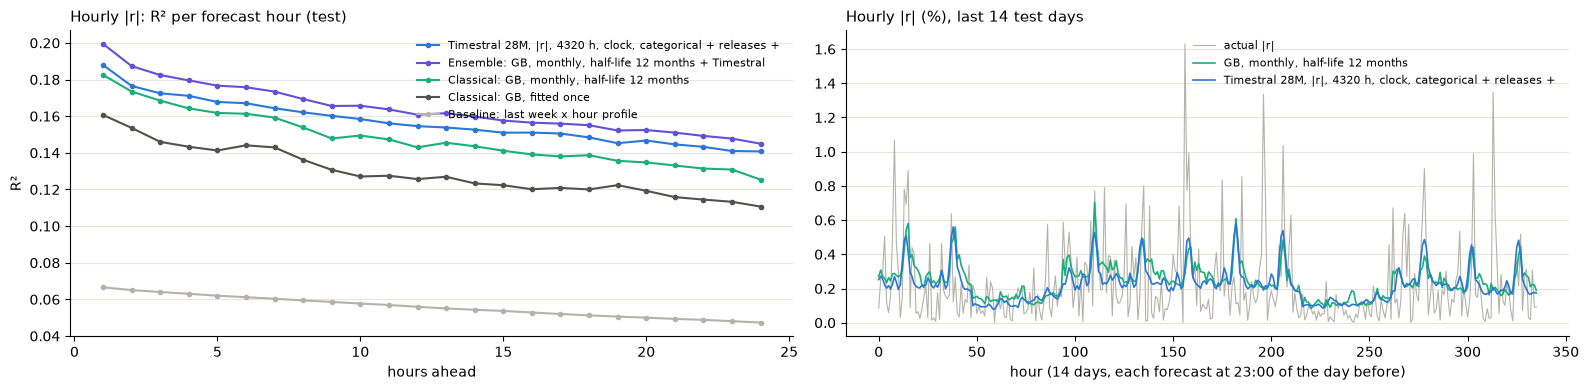

In [8]:
t0 = time.time()
q_test = timestral_quantiles(P["test"], TS["series"], TS["ctx"], TS["covs"], TS["repo"])
e_test = expected_abs(q_test).reshape(-1)
if TS_RESCALE:
    lin_tv = LinearRegression().fit(np.r_[TS["e"]["cal"], TS["e"]["val"]][:, None], np.r_[ya["cal"], ya["val"]])
    abs_val[TS_NAME] = TS["lin"].predict(TS["e"]["val"][:, None])
    abs_test[TS_NAME] = lin_tv.predict(e_test[:, None])
    print(f"rescaling refitted on train + validation: a {lin_tv.intercept_:+.3f}, b {lin_tv.coef_[0]:.3f}")
else:
    abs_val[TS_NAME], abs_test[TS_NAME] = TS["e"]["val"], e_test
print(f"test forecast: {len(P['test']):,} origins in {time.time() - t0:.0f} s")

ENS = {f"Ensemble: {r.split(': ')[1]} + Timestral": [r, TS_NAME] for r in REFS}
for e, members in ENS.items():
    abs_val[e] = np.mean([abs_val[m] for m in members], axis=0)
    abs_test[e] = np.mean([abs_test[m] for m in members], axis=0)

abs_tab = pd.DataFrame.from_dict({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], v),
                                       "test MAE": mean_absolute_error(ya["test"], v), "test corr": safe_corr(v, ya["test"])}
                                   for k, v in abs_test.items()}, orient="index")
with pd.option_context("display.max_colwidth", 70):
    display(abs_tab.round(4))
CANDIDATES = [TS_NAME] + list(ENS)
TS_CHOSEN = abs_tab.loc[CANDIDATES, "val R2"].idxmax()
REF_BEST = abs_tab.loc[REFS, "val R2"].idxmax()
print(f"chosen on validation: {TS_CHOSEN}")
print(f"best classical reference on validation: {REF_BEST}")
print(f"test R2: {abs_tab.loc[TS_CHOSEN, 'test R2']:.4f} against {abs_tab.loc[REF_BEST, 'test R2']:.4f} "
      f"({abs_tab.loc[TS_CHOSEN, 'test R2'] - abs_tab.loc[REF_BEST, 'test R2']:+.4f})")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ac = ya["test"].reshape(-1, 24)
lines = [(TS_NAME, BLUE)] + [(k, c) for k, c in [(GB_REFIT, AQUA), (GB_ABS, INK)] if k in abs_test] + [(RULE, GREY)]
if TS_CHOSEN != TS_NAME:
    lines.insert(1, (TS_CHOSEN, PURPLE))
for k, c in lines:
    pr = abs_test[k].reshape(-1, 24)
    ax[0].plot(range(1, 25), [U.r2(ac[:, j], pr[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k[:60])
ax[0].set_xlabel("hours ahead")
ax[0].set_ylabel("R²")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Hourly |r|: R² per forecast hour (test)")
seg = test_days[-14:]                                                # last 14 days, one origin per day
ax[1].plot(np.abs(Y["test"][seg]).reshape(-1), lw=0.8, color=GREY, label="actual |r|")
ax[1].plot(abs_test[REF_BEST].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=AQUA, label=REF_BEST[11:])
ax[1].plot(abs_test[TS_NAME].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=BLUE, label=TS_NAME[:60])
ax[1].set_xlabel("hour (14 days, each forecast at 23:00 of the day before)")
ax[1].legend(frameon=False, fontsize=8)
tidy(ax[1], "Hourly |r| (%), last 14 test days")
plt.tight_layout()
plt.show()

SUMMARY.append({"question": "size of each of the next 24 hours (|r|)", "Timestral (chosen without the test)": TS_CHOSEN,
                "test result": f"R2 {abs_tab.loc[TS_CHOSEN, 'test R2']:.3f} (Timestral alone {abs_tab.loc[TS_NAME, 'test R2']:.3f})",
                "classical reference (refitted here)": "; ".join(f"{k[11:]}: R2 {abs_tab.loc[k, 'test R2']:.3f}" for k in REFS)})

### 3.4 How sure are we?

The moving-block bootstrap of `neural-models.ipynb` (section 7): the 829 independent test days are resampled in blocks of 10 days, 1,000 times, each day bringing its 24 test origins. A difference whose 95% interval does not include 0 is reliable.

In [9]:
def day_orig(idx):
    # all test origins of the chosen independent days (the last day may be incomplete)
    o = (test_days[idx][:, None] + np.arange(24)).ravel()
    return o[o < len(P["test"])]


days_rows = lambda idx: rows24(day_orig(idx))                        # their 24 long-format rows each
r2_days = lambda pred, i: U.r2(ya["test"][days_rows(i)], pred[days_rows(i)])
boot_stats = {f"hourly |r| R², {TS_CHOSEN}": lambda i: r2_days(abs_test[TS_CHOSEN], i)}
for ref in REFS:
    boot_stats[f"{TS_NAME} − {ref[11:]}"] = lambda i, ref=ref: r2_days(abs_test[TS_NAME], i) - r2_days(abs_test[ref], i)
for e in ENS:
    boot_stats[f"{e} − {ENS[e][0][11:]}"] = lambda i, e=e: r2_days(abs_test[e], i) - r2_days(abs_test[ENS[e][0]], i)
boot_rows = {}
for name, fn in boot_stats.items():
    b = U.block_bootstrap(fn, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
    boot_rows[name] = {"estimate": fn(np.arange(ND)), "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5),
                       "share of resamples > 0": (b > 0).mean()}
with pd.option_context("display.max_colwidth", 90):
    display(pd.DataFrame(boot_rows).T.round(4))

,estimate,CI 2.5%,CI 97.5%,share of resamples > 0
"hourly |r| R², Ensemble: GB, monthly, half-life 12 months + Timestral",0.1643,0.1420,0.1875,1.000
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume − GB, fitted once",0.0275,0.0190,0.0357,1.000
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume − GB, monthly, half-life 12 months",0.0091,0.0026,0.0161,0.998
"Ensemble: GB, fitted once + Timestral − GB, fitted once",0.0297,0.0246,0.0351,1.000
"Ensemble: GB, monthly, half-life 12 months + Timestral − GB, monthly, half-life 12 months",0.0164,0.0132,0.0200,1.000


### 3.5 What we see

**Answer: yes. Timestral 28M, used zero-shot, has test R² 0.157, reliably above Gradient Boosting refitted every month (0.148): +0.009, interval [+0.003, +0.016], better in 99.8% of the resamples. The candidate chosen on validation, its average with that Gradient Boosting, reaches 0.164: +0.016, interval [+0.013, +0.020].**

| Model | val R² | test R² |
|---|---|---|
| Last week × hour profile | 0.0497 | 0.0560 |
| Gradient Boosting, fitted once / refitted monthly | 0.0947 / 0.1005 | 0.1295 / 0.1479 |
| Timestral 28M, \|r\|, 180 days, clock + releases + range and volume | 0.1199 | 0.1570 |
| Average with Gradient Boosting fitted once / refitted monthly (chosen) | 0.1208 / **0.1213** | 0.1592 / **0.1643** |
| *For reference, `neural-models.ipynb`: LSTM fine-tuned monthly / average of three families* | *0.1208 / 0.1197* | *0.1556 / 0.1611* |

- **The model must read the size of the moves.** With the series \|r\| the validation R² is 0.108; with the returns r, and the size taken from the spread of the forecast, only 0.067.
- **More history helps:** 30, 90 and 180 days give 0.088, 0.105 and 0.108, still rising at the longest context tried.
- **Covariates: the release calendar and the range help, the clock does not.** The clock adds +0.0003 as categories and −0.0003 as numbers: Timestral already finds the hour profile in the context. The release hours add +0.008 and the range and volume of the past hours +0.004. With them, Timestral without any training (0.120) matches the best validation score of `neural-models.ipynb` (0.121) and beats Gradient Boosting (0.101).
- **The rescaling is not needed.** Fitted on the train origins of 2020–2022, a wilder period (b ≈ 0.84), it lowers every validation score, so the raw forecast is chosen: its mean \|r\| is already on the right scale.
- **Averages help.** Timestral and Gradient Boosting make different errors: the average with the monthly refit adds +0.016 to Gradient Boosting and +0.007 to Timestral alone. Validation barely separated it from Timestral alone (+0.0014), but it is also better on test.
- **Like every model of the project, Timestral scores higher on test than on validation** (0.120 → 0.157): the test block (mid-2024 to 2026) is easier to forecast.
- **Model size:** in an earlier run the 209M model gave 0.1253 on validation and 0.160 on test (average with Gradient Boosting 0.166), +0.003 over the 28M on test for 7× the time (3.2 h for the test block). It is not worth it on this hardware (section 3.2).

### 3.6 Exporting the models

The models of this section are saved in `EXPORT_DIR/<id>/`, where `<id>` is the name of the candidate chosen on validation (`TS_CHOSEN`) in lower case, so the folder says which model is the best one:

- **`models.joblib`**: a dict `{"best": TS_CHOSEN, "models": {name: model}}` with every model of the table of section 3.3 except the baseline rule:
  - Gradient Boosting fitted once on train + validation (the model scored on test);
  - Gradient Boosting refitted for the month after the data: every pool row, with the half-life of 12 months counted from the last hour (with `RUN_GB_REFIT`);
  - Timestral, as its setting: repo, revision, series, context, covariates and rescaling. Nothing of Timestral is trained here, so its weights are not copied: `TimestralForecaster.from_pretrained(repo, revision=...)` downloads them again;
  - the averages, as the list of the models they average.
- **`metadata.json`**: the id, the best model and its members, the columns and setting of Gradient Boosting, the hour profile used by `tgt_hour_profile`, the data period and the validation and test scores of every exported model.

To load them: `bundle = joblib.load(os.path.join(EXPORT_DIR, EXPORT_ID, "models.joblib"))`, then `bundle["models"][bundle["best"]]`. The Gradient Boosting models read the long-format rows of `Xl(block, BASE, H_BASE + B3)` (section 1.3).


In [10]:
EXPORT_ID = re.sub(r"[^a-z0-9]+", "-", TS_CHOSEN.lower()).strip("-")   # the model chosen on validation names the export
export_path = os.path.join(EXPORT_DIR, EXPORT_ID)
os.makedirs(export_path, exist_ok=True)

ts_spec = {"repo": TS["repo"], "revision": REVISIONS.get(TS["repo"]), "series": TS["series"], "context hours": TS["ctx"],
           "covariates": list(TS["covs"]),
           "rescaling a, b": [float(lin_tv.intercept_), float(lin_tv.coef_[0])] if TS_RESCALE else None}
MODELS = {GB_ABS: gb_once, TS_NAME: ts_spec}
if RUN_GB_REFIT:
    # the monthly refit for the month after the data: every pool row, weighted by its age at the last hour
    w = 0.5 ** ((hourly.index[-1] - pool_origin) / pd.Timedelta(days=30.44) / 12)
    MODELS[GB_REFIT] = make_abs_gb(**p_abs_gb).fit(X_pool, y_pool, sample_weight=w)
MODELS.update({e: {"average of": members} for e, members in ENS.items()})
assert TS_CHOSEN in MODELS
joblib.dump({"best": TS_CHOSEN, "models": MODELS}, os.path.join(export_path, "models.joblib"))

meta = {"id": EXPORT_ID, "best": TS_CHOSEN, "best members": ENS.get(TS_CHOSEN, [TS_CHOSEN]),
        "target": "|r| (%) of each of the next 24 hours, long format (24 rows per origin, origin-major)",
        "data": [str(hourly.index[0]), str(hourly.index[-1])],
        "gb columns": BASE + H_BASE + B3, "gb setting": p_abs_gb, "hour profile": HOUR_PROFILE.tolist(),
        "timestral": ts_spec,
        "scores": abs_tab.loc[list(MODELS), ["val R2", "test R2", "test MAE"]].round(4).to_dict(orient="index"),
        "exported": pd.Timestamp.now().isoformat(timespec="seconds")}
with open(os.path.join(export_path, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print(f"exported to {export_path}: {', '.join(MODELS)}")
print(f"best (chosen on validation): {TS_CHOSEN}   test R2 {abs_tab.loc[TS_CHOSEN, 'test R2']:.4f}")

exported to models\ensemble-gb-monthly-half-life-12-months-timestral: Classical: GB, fitted once, Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume, Classical: GB, monthly, half-life 12 months, Ensemble: GB, fitted once + Timestral, Ensemble: GB, monthly, half-life 12 months + Timestral
best (chosen on validation): Ensemble: GB, monthly, half-life 12 months + Timestral   test R2 0.1643


## 4. Hourly prediction ranges

**Question.** Timestral forecasts quantiles directly. Is its 80% range, [q10, q90] of the return of each predicted hour, as honest and as narrow as the one of `classical-models.ipynb` (section 7)?

**To beat.** Gradient Boosting quantile regression (q10, q50, q90 on the long format, base + B3, the setting of `classical-models.ipynb`), refitted here: coverage 77.9% raw and **80.0% with rolling conformal calibration** (30 days), width 0.98%, but only **56% in release hours**. The metrics are those of `classical-models.ipynb`: coverage (should be 80%), width, coverage in the calmest, middle and wildest third of the hours (by `rule_abs`), coverage and width in release hours, and the pinball losses of q10 and q90.

**Timestral.** The quantiles of the return series r, with the context, covariates and model chosen in section 3.2 (if the chosen series was \|r\|, the same setting is run again on r). To keep the run short this section uses every 6th test origin (`Q_STRIDE`; about 79,500 predicted hours), and every range in the table is scored on those same rows. Rolling conformal calibration is applied to it in the same way: the interval becomes centre ± f × half-width, where f is the 80% quantile of \|y − centre\| / half-width over the test hours of the last 30 days whose outcome was known at the start of the day.

As a side result, the **median** of the forecast is a point forecast of the returns, the assigned task: its MAE skill against the zero forecast is printed below.

Validation block (raw ranges; models fitted on train, Timestral as it comes)


,coverage,width %,coverage calm,coverage middle,coverage wild,coverage release hours,width release hours %,pinball q10,pinball q90
Gradient Boosting quantile (raw),0.8008,0.8827,0.7879,0.796,0.8185,0.4861,1.0820,0.0805,0.0810
Timestral (raw),0.8009,0.9032,0.7943,0.802,0.8063,0.5764,1.5538,0.0798,0.0808


Test block (every 6th origin)


,coverage,width %,coverage calm,coverage middle,coverage wild,coverage release hours,width release hours %,pinball q10,pinball q90
Baseline: fixed range,0.8762,1.2798,0.9467,0.8829,0.7991,0.6636,1.2798,0.0922,0.0912
Baseline: volatility-scaled,0.7920,0.9555,0.7866,0.7818,0.8075,0.5070,1.0144,0.0861,0.0843
Gradient Boosting quantile (raw),0.7780,0.9186,0.7662,0.7722,0.7954,0.5350,1.1103,0.0827,0.0804
"Gradient Boosting quantile, rolling conformal 30 days",0.7994,0.9816,0.7826,0.7927,0.8229,0.5584,1.1815,0.0828,0.0806
Timestral (raw),0.8029,0.9935,0.8113,0.7921,0.8054,0.6963,1.5001,0.0825,0.0800
"Timestral, rolling conformal 30 days",0.7991,0.9991,0.7934,0.7893,0.8146,0.6963,1.5071,0.0828,0.0804


MAE skill of the median against the zero forecast (assigned task): Timestral -0.0015, Gradient Boosting q50 -0.0007   (17 s)


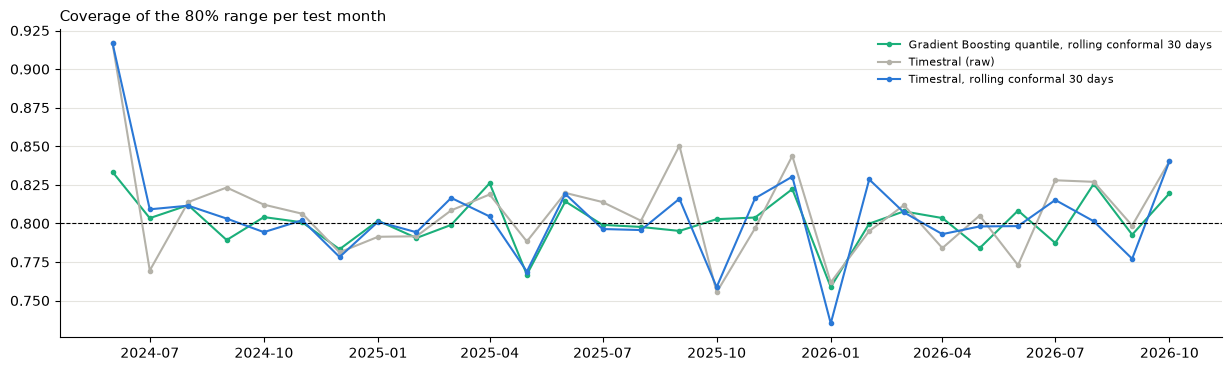

In [11]:
t0 = time.time()
qs = np.arange(0, len(P["test"]), Q_STRIDE)                         # every Q_STRIDE-th test origin: block "tq"
P["tq"], Y["tq"], D["tq"] = P["test"][qs], Y["test"][qs], D["test"][qs]
XA["tq"] = XA["test"][rows24(qs)]
if TS["series"] == "r":
    q_val_r, q_test_r = TS["q"]["val"], q_test[qs]
else:
    q_val_r = timestral_quantiles(P["val"], "r", TS["ctx"], TS["covs"], TS["repo"])
    q_test_r = timestral_quantiles(P["tq"], "r", TS["ctx"], TS["covs"], TS["repo"])
i10, i50, i90 = (int(np.flatnonzero(np.isclose(LEVELS, lv))[0]) for lv in (0.1, 0.5, 0.9))
ts_q = {b: q.reshape(-1, len(LEVELS))[:, [i10, i50, i90]] for b, q in (("val", q_val_r), ("test", q_test_r))}

TAUS = (0.1, 0.5, 0.9)
make_q = lambda tau: HistGradientBoostingRegressor(loss="quantile", quantile=tau, early_stopping=False, max_iter=200,
                                                   learning_rate=0.05, max_depth=3, min_samples_leaf=200, random_state=RANDOM_STATE)
yr = {k: yl(k, "ret") for k in ("train", "val", "tq", "tv")}
gb_q = {"val": np.sort(np.column_stack([make_q(t).fit(XA["train"], yr["train"]).predict(XA["val"]) for t in TAUS]), axis=1),
        "test": np.sort(np.column_stack([save(f"hourly ranges: GB quantile {t}, train + validation", make_q(t).fit(XA["tv"], yr["tv"]))
                                         .predict(XA["tq"]) for t in TAUS]), axis=1)}


def interval_row(block, lo, hi):
    y, sig, rel = yr[block], rule_abs(block), release_rows(block)
    tercile = pd.qcut(sig, 3, labels=["calm", "middle", "wild"])
    inside = (y >= lo) & (y <= hi)
    return {"coverage": inside.mean(), "width %": (hi - lo).mean(),
            **{f"coverage {c}": inside[tercile == c].mean() for c in ["calm", "middle", "wild"]},
            "coverage release hours": inside[rel].mean(), "width release hours %": (hi - lo)[rel].mean(),
            "pinball q10": U.pinball(y, lo, 0.1), "pinball q90": U.pinball(y, hi, 0.9)}


print("Validation block (raw ranges; models fitted on train, Timestral as it comes)")
display(pd.DataFrame({"Gradient Boosting quantile (raw)": interval_row("val", gb_q["val"][:, 0], gb_q["val"][:, 2]),
                      "Timestral (raw)": interval_row("val", ts_q["val"][:, 0], ts_q["val"][:, 2])}).T.round(4))

# rolling conformal (classical-models.ipynb, section 7): f from the test hours known at the start of each day
y_q = yr["tq"]
known_at = (np.repeat(D["tq"], 24) + pd.to_timedelta(np.tile(np.arange(1, 25), len(D["tq"])), unit="h")).values
test_day = np.repeat(D["tq"].normalize(), 24).values


def rolling_f(centre, half, days_back):
    # f for each test day from the hours whose outcome was known at the start of that day
    score, f = np.abs(y_q - centre) / half, np.ones(len(centre))
    order = np.argsort(known_at)
    k_sorted, s_sorted = known_at[order], score[order]
    for d in np.unique(test_day):
        lo_i, hi_i = np.searchsorted(k_sorted, [d - np.timedelta64(days_back, "D"), d], side="right")
        if hi_i - lo_i >= 24 * 24 * 7 // Q_STRIDE:                   # at least a week of known outcomes; else f = 1
            f[test_day == d] = np.quantile(s_sorted[lo_i:hi_i], 0.8)
    return f


def rolling_conformal(lo, hi, days_back=30):
    centre, half = (lo + hi) / 2, (hi - lo) / 2
    f = rolling_f(centre, half, days_back)
    return centre - f * half, centre + f * half


sigma_tv = np.r_[rule_abs("train"), rule_abs("val")]
fixed, zq = np.quantile(yr["tv"], [0.1, 0.9]), np.quantile(yr["tv"] / sigma_tv, [0.1, 0.9])
sigma_te = rule_abs("tq")
intervals = {"Baseline: fixed range": (np.full(len(y_q), fixed[0]), np.full(len(y_q), fixed[1])),
             "Baseline: volatility-scaled": (sigma_te * zq[0], sigma_te * zq[1]),
             "Gradient Boosting quantile (raw)": (gb_q["test"][:, 0], gb_q["test"][:, 2]),
             "Gradient Boosting quantile, rolling conformal 30 days": rolling_conformal(gb_q["test"][:, 0], gb_q["test"][:, 2]),
             "Timestral (raw)": (ts_q["test"][:, 0], ts_q["test"][:, 2]),
             "Timestral, rolling conformal 30 days": rolling_conformal(ts_q["test"][:, 0], ts_q["test"][:, 2])}
conf_tab = pd.DataFrame({k: interval_row("tq", *v) for k, v in intervals.items()}).T
print(f"Test block (every {Q_STRIDE}th origin)")
display(conf_tab.round(4))
mae_skill = lambda med: 1 - np.abs(y_q - med).mean() / np.abs(y_q).mean()
print(f"MAE skill of the median against the zero forecast (assigned task): Timestral {mae_skill(ts_q['test'][:, 1]):+.4f}, "
      f"Gradient Boosting q50 {mae_skill(gb_q['test'][:, 1]):+.4f}   ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(15, 4))
month_q = np.repeat(D["tq"].to_period("M"), 24)
for k, c in [("Gradient Boosting quantile, rolling conformal 30 days", AQUA), ("Timestral (raw)", GREY),
             ("Timestral, rolling conformal 30 days", BLUE)]:
    lo, hi = intervals[k]
    cov = pd.Series((y_q >= lo) & (y_q <= hi)).groupby(month_q).mean()
    ax.plot(cov.index.to_timestamp(), cov.values, marker=".", color=c, label=k)
ax.axhline(0.8, c="k", ls="--", lw=0.8)
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Coverage of the 80% range per test month")
plt.show()

best_ts_range = conf_tab.loc["Timestral, rolling conformal 30 days"]
SUMMARY.append({"question": "80% range for each of the next 24 hours", "Timestral (chosen without the test)": "Timestral + rolling conformal (30 days)",
                "test result": f"coverage {best_ts_range['coverage']:.1%}, width {best_ts_range['width %']:.2f}%; "
                               f"release hours {best_ts_range['coverage release hours']:.0%} (raw: coverage {conf_tab.loc['Timestral (raw)', 'coverage']:.1%})",
                "classical reference (refitted here)": "GB quantile + rolling conformal: coverage "
                                                       f"{conf_tab.loc['Gradient Boosting quantile, rolling conformal 30 days', 'coverage']:.1%}, width "
                                                       f"{conf_tab.loc['Gradient Boosting quantile, rolling conformal 30 days', 'width %']:.2f}%; release hours "
                                                       f"{conf_tab.loc['Gradient Boosting quantile, rolling conformal 30 days', 'coverage release hours']:.0%}"})

### 4.1 What we see

**Answer: as honest and as narrow as the classical range, without any calibration, and better in release hours.** On every 6th test origin:

| Range | coverage | width | coverage calm / middle / wild | release hours: coverage, width |
|---|---|---|---|---|
| Gradient Boosting quantile, raw | 77.8% | 0.92% | 76.6% / 77.2% / 79.5% | 54%, 1.11% |
| Gradient Boosting quantile, rolling conformal | 79.9% | 0.98% | 78.3% / 79.3% / 82.3% | 56%, 1.18% |
| **Timestral, raw** | **80.3%** | **0.99%** | 81.1% / 79.2% / 80.5% | **70%, 1.50%** |
| Timestral, rolling conformal | 79.9% | 1.00% | 79.3% / 78.9% / 81.5% | 70%, 1.51% |

- **Timestral's own quantiles are calibrated:** 80.3% coverage on test and 80.1% on validation, as they come. Gradient Boosting needs the rolling conformal step to reach 80%; for Timestral the step changes nothing. Its pinball losses are a little lower (q10 0.0825 against 0.0827, q90 0.0800 against 0.0804).
- **The coverage is even across calm and wild hours** (79–81%), which a useful range needs.
- **Release hours are the real difference.** With the release calendar as a known-future covariate, Timestral widens the range of those hours (1.50% against 1.18%) and covers 70% of their moves, against 56% for Gradient Boosting. Still below 80%: the size of a release move is not known in advance.
- **The median is no better than 0%** (MAE skill −0.0015), like every model of the project: Timestral, too, finds no direction in the hourly returns.

## 5. Conclusions

### 5.1 This run

In [12]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(SUMMARY).set_index("question"))
print(f"Total run time: {(time.time() - T_START) / 60:.1f} minutes")

,Timestral (chosen without the test),test result,classical reference (refitted here)
question,,,
size of each of the next 24 hours (|r|),"Ensemble: GB, monthly, half-life 12 months + Timestral",R2 0.164 (Timestral alone 0.157),"GB, fitted once: R2 0.130; GB, monthly, half-life 12 months: R2 0.148"
80% range for each of the next 24 hours,Timestral + rolling conformal (30 days),"coverage 79.9%, width 1.00%; release hours 70% (raw: coverage 80.3%)","GB quantile + rolling conformal: coverage 79.9%, width 0.98%; release hours 56%"


Total run time: 2.7 minutes


### 5.2 Conclusions

1. **A pretrained model, used as it comes, beats the models trained on our data** for the size of the hourly moves. Timestral 28M reaches test R² 0.157, reliably above Gradient Boosting refitted every month (0.148) and level with the best network of `neural-models.ipynb` (0.156), which needed hour features, a volume attention mask and monthly fine-tuning. Averaged with Gradient Boosting it reaches 0.164, the best result of the project for this question.
2. **What matters is what the model reads**: the size of the moves rather than the returns, a long context (180 days), and the release calendar as known-future information. The clock adds nothing, since the model finds the hour profile in the context.
3. **Its prediction ranges are honest without calibration** (80.3% coverage for an 80% range) and, thanks to the release calendar, cover 70% of the release-hour moves, against 56% for the classical ranges.
4. **The returns stay unpredictable**: the median of the forecast does not beat 0%, the result of every notebook.
5. **The small model is enough.** The 209M model adds about 0.003 R² on test for 7× the compute; with the 28M the whole notebook runs in about an hour on a laptop GPU.
6. **The caveat holds.** Timestral was released after our test block and Mistral does not list its real training series. If Bitcoin 2023–2026 is among them, the validation and test results are optimistic. The gains over Gradient Boosting are reliable within this test block, but cannot be called out-of-sample for the model.

### 5.3 Not done here

- **Fine-tuning.** The `timestral` package only forecasts (`forecast` runs under `torch.inference_mode()`), and Mistral offers fine-tuning only through its paid platform. The network itself, `TimestralModel.predict_block`, is a plain PyTorch module, so it can be trained with our own loop: the pinball loss over the 21 quantiles (Timestral's own training loss), a low learning rate, few epochs and early stopping on its own block, possibly only the last layers. Fine-tuned every month, it would be the counterpart of the monthly refits.
- **Next-day volatility** from the same forecast: the expected squared return of each predicted hour, summed over the 24 hours.
- **Longer contexts** (up to 32,768 hours) and the 5M and 123M models.